# How metadynamics bias comes into play: states, χ(t), and reweighting

This notebook has two parts:

1. **Real data** — load an actual omega trajectory from this project (`ct_data_omg/timeomega.dat`),
   discretize it into cis/trans states with the exact same `omega2cistrans` function used in
   [extract_omega.ipynb](extract_omega.ipynb), and plot χ(t) in the same style as the reference figure
   (0/1 dots vs. time step).
2. **Synthetic toy model** — a small 1D metadynamics simulation on a *known* asymmetric double well,
   so we know the ground-truth population. This lets us directly show, side by side:
   - the **naive** (unweighted) population — just counting time spent in each state,
   - the **bias-reweighted** population — `exp(V_bias(t)/kT)`-weighted counting (the formula used in
     `extract_omega.ipynb` on the real `pb.bias` column),
   - the **naive transition-matrix** stationary distribution (the `TransitionMatrix*.ipynb` approach),

   and compare all three against the true answer.

   Note: the pared-down local `.dat` files (`timeomega*.dat`) only kept `time, omega1, omega2, omega3` —
   the `pb.bias` column was dropped when they were extracted from the full PLUMED COLVAR files. So the
   real-data section can only show you the *states*; to see the bias mechanics with a known right answer,
   part 2 builds a transparent synthetic example instead.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)
plt.rcParams['figure.dpi'] = 110

## Part 1 — Real data: turning a real omega trajectory into χ(t)

This is exactly the `omega2cistrans` function from `extract_omega.ipynb` / `transition_matrix_res.ipynb`:
omega (radians) → degrees → shifted into `(-90°, 270°)` → `1` (trans) if the shifted angle is `> 90°`,
else `0` (cis).

In [2]:
def omega2cistrans(omega_deg):
    """omega angles in degrees -> 0 (cis) / 1 (trans)."""
    shifted = (omega_deg + 90.0) % 360.0 - 90.0
    return np.where(shifted > 90.0, 1, 0).astype(int)

omega_file = "cis-trans-pbmetad/ct_data_omg/timeomega.dat"
df = pd.read_csv(omega_file, sep=r"\s+")
df.head()

,time,omega1,omega2,omega3
0,0.02,2.920844,2.893401,3.098204
1,0.42,2.260316,-2.611256,2.729368
2,0.82,3.064625,-2.870014,-3.013302
3,1.22,2.873185,3.028340,3.049154
4,1.62,-3.065443,-3.050443,2.147561


In [3]:
omega_deg = df[['omega1', 'omega2', 'omega3']].to_numpy() * (180 / np.pi)
cistrans = np.stack([omega2cistrans(omega_deg[:, i]) for i in range(3)], axis=1)

dt_ns = 0.0004  # matches transition_matrix_res.ipynb (PB-metaD omega run)
print("trajectory length:", cistrans.shape[0], "frames  (~%.1f ns)" % (cistrans.shape[0]*dt_ns))
print("naive (raw count) trans fraction per residue:", cistrans.mean(axis=0))

trajectory length: 2753849 frames  (~1101.5 ns)
naive (raw count) trans fraction per residue: [0.66171348 0.50992701 0.53841224]


### χ(t) for residue 1, a short window

Same style as the reference plot: filled circles at `1` (trans) or `0` (cis) vs. time step.

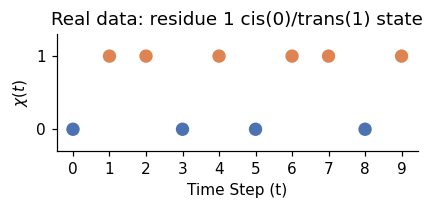

In [4]:
res = 0
start, stride, n_points = 180_000, 100, 10   # a window that actually shows cis/trans flips
window = cistrans[start:start + stride * n_points:stride, res]

fig, ax = plt.subplots(figsize=(4, 2))
colors = ['#4c72b0' if s == 0 else '#dd8452' for s in window]
ax.scatter(range(len(window)), window, c=colors, s=60, zorder=3)
ax.set_yticks([0, 1])
ax.set_ylim(-0.3, 1.3)
ax.set_xticks(range(len(window)))
ax.set_xlabel("Time Step (t)")
ax.set_ylabel(r"$\chi(t)$")
ax.set_title(f"Real data: residue {res+1} cis(0)/trans(1) state")
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

This is genuine simulation output — but because the pared-down `.dat` file has no `pb.bias`
column, all we can show here is the *state trajectory* itself, not how the bias reshaped it. That's
what Part 2 is for.

## Part 2 — Synthetic metadynamics: watching the bias flatten a known landscape

We build a 1D asymmetric double well `U(x)` with a **known** true population split (so we have
a ground truth to check against), run overdamped Langevin dynamics on it, and periodically deposit
Gaussian hills (a standard metadynamics bias) that push the walker out of whichever well it's
currently sitting in — exactly what PLUMED's (PB)MetaD does to the real omega coordinate.

- `x < 0` → state "0" (deep well, true majority state)
- `x >= 0` → state "1" (shallow well, true minority state)

In [5]:
def U(x):
    return (x**2 - 1)**2 + 0.4 * x   # asymmetric double well: deep minimum at x=-1, shallow at x=+1

def dUdx(x):
    return 4 * x * (x**2 - 1) + 0.4

kT = 0.5     # thermal energy (arbitrary units)
gamma = 1.0  # friction
dt = 0.01
nsteps = 400_000

# Ground truth: direct numerical integration of the Boltzmann weight exp(-U/kT) (no dynamics, no bias)
xs = np.linspace(-3, 3, 200_000)
w_true = np.exp(-U(xs) / kT)
w_true /= w_true.sum()
true_pop = np.array([w_true[xs < 0].sum(), w_true[xs >= 0].sum()])
print(f"True population   [state0, state1] = {true_pop.round(3)}")

True population   [state0, state1] = [0.8 0.2]


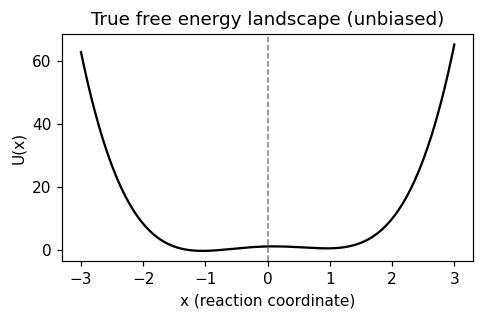

In [6]:
fig, ax = plt.subplots(figsize=(4.5, 3))
ax.plot(xs, U(xs), color='k')
ax.axvline(0, color='gray', ls='--', lw=1)
ax.set_xlabel("x (reaction coordinate)")
ax.set_ylabel("U(x)")
ax.set_title("True free energy landscape (unbiased)")
plt.tight_layout()
plt.show()

### Run the biased (metadynamics) simulation

Bias is accumulated on a grid: every `deposit_stride` steps we add a Gaussian hill centered at the
walker's current position. This is the same idea as `pb.bias` in the real PLUMED output — it's the
instantaneous value of the accumulated bias potential *at the walker's current position and time*.

In [7]:
grid = np.linspace(-3, 3, 601)
dx = grid[1] - grid[0]
bias_grid = np.zeros_like(grid)

hill_h = 0.01        # hill height
hill_sigma = 0.15    # hill width
deposit_stride = 200 # deposit a new hill every this many steps

def bias_at(x):
    return np.interp(x, grid, bias_grid)

def biasforce_at(x):
    dbias = np.gradient(bias_grid, dx)
    return np.interp(x, grid, dbias)

x = -1.0
states = np.zeros(nsteps, dtype=int)
bias_traj = np.zeros(nsteps)     # this plays the exact role of the 'pb.bias' column

for t in range(nsteps):
    force = -dUdx(x) - biasforce_at(x)
    x += force * dt / gamma + np.sqrt(2 * kT * dt / gamma) * rng.normal()
    x = np.clip(x, grid[0] + 1e-6, grid[-1] - 1e-6)
    states[t] = 1 if x >= 0 else 0
    bias_traj[t] = bias_at(x)
    if t % deposit_stride == 0:
        bias_grid += hill_h * np.exp(-(grid - x) ** 2 / (2 * hill_sigma ** 2))

print("done:", nsteps, "steps")

done: 400000 steps


### χ(t) and the growing bias, side by side

Watch how the bias (bottom panel) climbs as the walker revisits the deep well, and how that
eventually lets it escape into state 1 more than it "should" — the whole point of metadynamics.

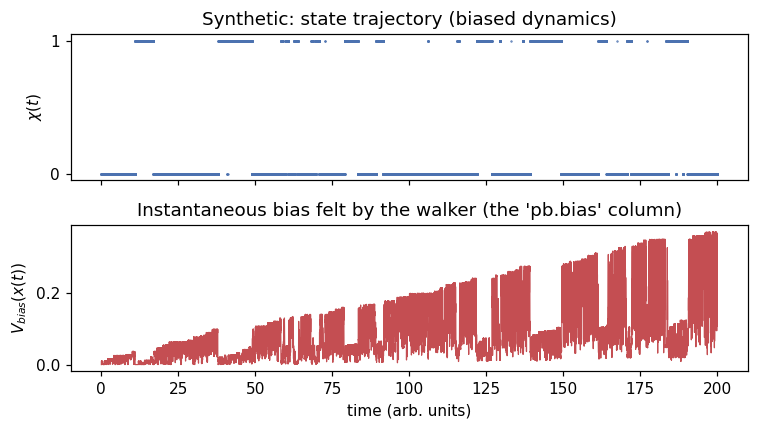

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True)

window = slice(0, 20000)
t_ns = np.arange(nsteps)[window] * dt

axes[0].plot(t_ns, states[window], '.', ms=1, color='#4c72b0')
axes[0].set_yticks([0, 1])
axes[0].set_ylabel(r"$\chi(t)$")
axes[0].set_title("Synthetic: state trajectory (biased dynamics)")

axes[1].plot(t_ns, bias_traj[window], color='#c44e52', lw=0.8)
axes[1].set_ylabel(r"$V_{bias}(x(t))$")
axes[1].set_xlabel("time (arb. units)")
axes[1].set_title("Instantaneous bias felt by the walker (the 'pb.bias' column)")

plt.tight_layout()
plt.show()

### Three ways to turn this trajectory into a population

1. **Naive counting** — just the fraction of frames in each state. This is what a plain histogram
   of `χ(t)` gives you, and it's what the *unweighted* `TransitionMatrix*.ipynb` stationary
   distribution effectively reproduces too (shown below).
2. **Bias-reweighted counting** — exactly the formula from `extract_omega.ipynb`:
   `P(state) = Σ exp(V_bias/kT) over frames in that state / Σ exp(V_bias/kT) over all frames`.
3. **Naive (unweighted) transition matrix** — build a lag-1 count/transition matrix directly on
   `χ(t)` and take its stationary eigenvector, the same way `transition_matrix_res.ipynb` does.

In [9]:
# 1. naive counting
naive_pop = np.array([(states == 0).mean(), (states == 1).mean()])

# 2. bias-reweighted counting (identical formula to extract_omega.ipynb, just with kT=0.5 instead of 2.5)
w = np.exp(bias_traj / kT)
reweighted_pop = np.array([w[states == 0].sum(), w[states == 1].sum()]) / w.sum()

# 3. naive (unweighted) transition matrix -> stationary distribution
lag = 1
T = np.zeros((2, 2))
for a, b in zip(states[:-lag], states[lag:]):
    T[a, b] += 1
T /= T.sum(axis=1, keepdims=True)
evals, evecs = np.linalg.eig(T.T)
pi = np.real(evecs[:, np.argmin(np.abs(evals - 1))])
msm_pop = pi / pi.sum()

results = pd.DataFrame(
    {
        "true (ground truth)": true_pop,
        "naive counting": naive_pop,
        "bias-reweighted": reweighted_pop,
        "naive transition matrix": msm_pop,
    },
    index=["state 0", "state 1"],
).T
results.round(3)

,state 0,state 1
true (ground truth),0.800,0.200
naive counting,0.574,0.426
bias-reweighted,0.808,0.192
naive transition matrix,0.574,0.426


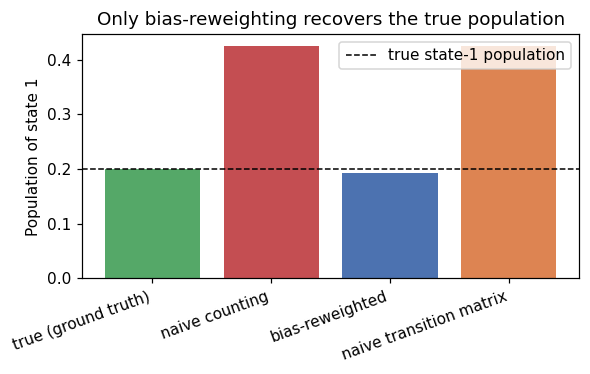

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
methods = results.index.tolist()
x_pos = np.arange(len(methods))
colors = ['#55a868', '#c44e52', '#4c72b0', '#dd8452']

ax.bar(x_pos, results['state 1'], color=colors)
ax.axhline(true_pop[1], color='k', ls='--', lw=1, label='true state-1 population')
ax.set_xticks(x_pos)
ax.set_xticklabels(methods, rotation=20, ha='right')
ax.set_ylabel("Population of state 1")
ax.set_title("Only bias-reweighting recovers the true population")
ax.legend()
plt.tight_layout()
plt.show()

### The takeaway

- The metadynamics bias visibly **flattens** the sampling: `naive counting` and the `naive
  transition matrix` both land close to each other, and both are far from the truth — because
  neither one knows the trajectory was biased. The unweighted MSM approach in
  `transition_matrix_res.ipynb` is doing exactly this: building a stationary distribution out of
  biased-trajectory statistics with no bias correction.
- **Bias-reweighting** (the `exp(V_bias/kT)` formula from `extract_omega.ipynb`, reused in
  `convergence_over_time.ipynb` / `population_over_time_res.ipynb`) uses the same trajectory but
  down-weights frames according to how much bias was propping them up at that instant, and
  recovers the true population to within simulation noise.
- In the real PLUMED output this is the `pb.bias` column — one value per frame, exactly like
  `bias_traj` here. The pared-down `timeomega.dat` files used in Part 1 dropped that column, which
  is why any "population" computed straight from `ct_data_omg/timeomega.dat` (or from an unweighted
  transition matrix built on it) should be read as **biased-trajectory statistics, not the true
  equilibrium population** — you'd need the original COLVAR file's `pb.bias` column to reweight it
  properly.